# PidginMed-ASR — Speaker-Level Evaluation


In [1]:
# Run once in Colab if necessary:
%pip -q install jiwer matplotlib

import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from jiwer import wer, cer
from IPython.display import display


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 19.6 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# === Paths and options ===
# Colab users: mount Drive first, then run this cell.

BASE_DIR = Path("/content/drive/MyDrive/anon/pidgindataset2026October/")
INPUT_DIR = BASE_DIR / 'outputRecent'
OUTPUT_DIR = INPUT_DIR / 'speaker_analysis'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    'Whisper': INPUT_DIR / 'Whisper_test_predictions.csv',
    'Canary': INPUT_DIR / 'Canary_test_predictions.csv',
    'MedASR': INPUT_DIR / 'MedASR_test_predictions.csv',
}

MEDICAL_ONLY = False


In [4]:
# === Read model outputs; preserve stable sample IDs ===
def speaker_from_path(path):
    if pd.isna(path):
        return None
    match = re.search(r'speaker[_\s-]?(\d+)', str(path), flags=re.IGNORECASE)
    return f'Speaker_{int(match.group(1))}' if match else None


def load_model_predictions(model, path):
    if not path.is_file():
        raise FileNotFoundError(f'{model}: Missing file: {path}')
    df = pd.read_csv(path, dtype={'sample_id': str})
    required = {'sample_id', 'reference', 'prediction'}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f'{model}: Missing columns: {sorted(missing)}')
    if df['sample_id'].isna().any() or df['sample_id'].duplicated().any():
        raise ValueError(f'{model}: Missing or duplicate sample IDs')
    if df['reference'].isna().any():
        raise ValueError(f'{model}: Missing reference transcriptions')

    if 'speaker_id' in df.columns and df['speaker_id'].notna().all():
        df['speaker_id'] = df['speaker_id'].astype(str).map(
            lambda s: speaker_from_path(s) or s
        )
    else:
        path_col = next((c for c in ('audio_path','audio_filepath') if c in df.columns), None)
        if path_col is None:
            raise ValueError(f'{model}: Need speaker_id or audio_path/audio_filepath')
        df['speaker_id'] = df[path_col].map(speaker_from_path)
    if df['speaker_id'].isna().any():
        raise ValueError(f'{model}: Could not identify speakers in {df.speaker_id.isna().sum()} rows')

    # Only apply the optional eligibility restriction; no new scoring method is introduced.
    if MEDICAL_ONLY:
        if 'medical_num_reference' in df.columns:
            df = df.loc[pd.to_numeric(df['medical_num_reference'], errors='coerce').gt(0)].copy()
        elif 'medical_exact_correct' in df.columns:
            df = df.loc[df['medical_exact_correct'].notna()].copy()
        else:
            raise ValueError(f'{model}: Medical eligibility indicator missing')

    df = df[['sample_id','reference','prediction','speaker_id']].copy()
    # Empty decoded speech is a valid ASR failure, NOT grounds for excluding the sample.
    df['prediction'] = df['prediction'].fillna('').astype(str)
    df['reference'] = df['reference'].astype(str)
    print(f'{model}: {len(df)} rows; {df.speaker_id.nunique()} speakers')
    return df

model_data = {model: load_model_predictions(model, path) for model,path in FILES.items()}


Whisper: 2245 rows; 5 speakers
Canary: 2245 rows; 5 speakers
MedASR: 2245 rows; 5 speakers


In [5]:
# === Align by sample_id and verify identical reference and speaker assignment ===
common_ids = set.intersection(*(set(df['sample_id']) for df in model_data.values()))
if not common_ids:
    raise ValueError('No shared sample_ids between model files')

# Require complete shared coverage to avoid silently dropping mismatched test examples.
for model, df in model_data.items():
    if len(common_ids) != len(df):
        missing = len(df) - len(common_ids)
        raise ValueError(f'{model}: {missing} sample(s) absent in another model output; resolve before analysis')

aligned = None
for model, df in model_data.items():
    frame = df.rename(columns={
        'reference': f'reference_{model}',
        'speaker_id': f'speaker_{model}',
        'prediction': f'prediction_{model}',
    })
    aligned = frame if aligned is None else aligned.merge(
        frame, on='sample_id', how='inner', validate='one_to_one'
    )

for model in ('Canary', 'MedASR'):
    if not aligned['reference_Whisper'].equals(aligned[f'reference_{model}']):
        bad = (aligned['reference_Whisper'] != aligned[f'reference_{model}']).sum()
        raise ValueError(f'Reference mismatch: Whisper / {model}: {bad} rows')
    if not aligned['speaker_Whisper'].equals(aligned[f'speaker_{model}']):
        raise ValueError(f'Speaker assignment mismatch: Whisper / {model}')

aligned = aligned.rename(columns={
    'reference_Whisper': 'reference', 'speaker_Whisper': 'speaker_id'
}).drop(columns=[
    'reference_Canary','reference_MedASR','speaker_Canary','speaker_MedASR'
]).sort_values(['speaker_id','sample_id']).reset_index(drop=True)

print(f'Validated aligned examples: {len(aligned)}; speakers: {aligned.speaker_id.nunique()}')
display(aligned.groupby('speaker_id').size().rename('num_samples').reset_index())


Validated aligned examples: 2245; speakers: 5


,speaker_id,num_samples
0,Speaker_1,499
1,Speaker_10,496
2,Speaker_17,251
3,Speaker_4,500
4,Speaker_6,499


In [6]:
# === Corpus-level WER and CER for each speaker/model ===
rows = []
for speaker, group in aligned.groupby('speaker_id', sort=True):
    references = group['reference'].tolist()
    for model in FILES:
        predictions = group[f'prediction_{model}'].tolist()
        rows.append({
            'speaker_id': speaker,
            'model': model,
            'num_samples': len(group),
            'wer': wer(references, predictions),
            'cer': cer(references, predictions),
        })

speaker_results = pd.DataFrame(rows)
summary = (speaker_results.groupby('model', as_index=False)
    .agg(num_speakers=('speaker_id','nunique'),
         mean_wer=('wer','mean'), std_wer=('wer','std'),
         mean_cer=('cer','mean'), std_cer=('cer','std')))

print('Speaker-level results:')
display(speaker_results)
print('Unweighted speaker mean/std (sample standard deviation):')
display(summary)


Speaker-level results:


,speaker_id,model,num_samples,wer,cer
0,Speaker_1,Whisper,499,0.303161,0.243083
1,Speaker_1,Canary,499,0.329788,0.252469
2,Speaker_1,MedASR,499,0.363243,0.178633
3,Speaker_10,Whisper,496,0.180811,0.143637
4,Speaker_10,Canary,496,0.243953,0.208128
5,Speaker_10,MedASR,496,0.231109,0.114029
6,Speaker_17,Whisper,251,0.259463,0.209695
7,Speaker_17,Canary,251,0.159255,0.105398
8,Speaker_17,MedASR,251,0.254416,0.119303
9,Speaker_4,Whisper,500,0.230863,0.171826


Unweighted speaker mean/std (sample standard deviation):


,model,num_speakers,mean_wer,std_wer,mean_cer,std_cer
0,Canary,5,0.256561,0.064474,0.198481,0.055139
1,MedASR,5,0.297093,0.056134,0.145169,0.027897
2,Whisper,5,0.225277,0.060414,0.178689,0.048074


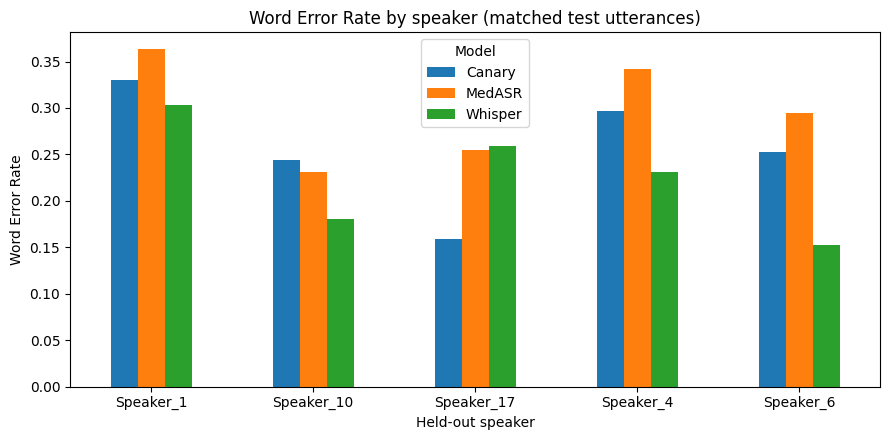

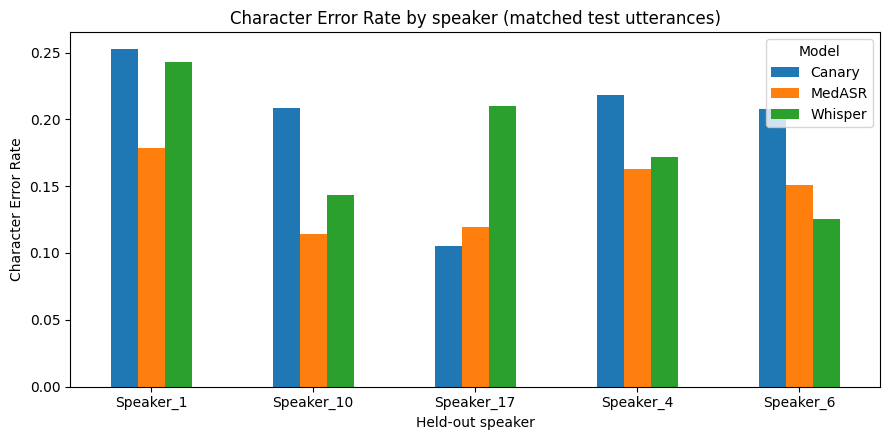

In [7]:
# === Plot WER and CER (separate figures) ===
for metric, ylabel in [('wer', 'Word Error Rate'), ('cer','Character Error Rate')]:
    pivot = speaker_results.pivot(index='speaker_id', columns='model', values=metric)
    ax = pivot.plot(kind='bar', figsize=(9,4.5), rot=0)
    ax.set_xlabel('Held-out speaker')
    ax.set_ylabel(ylabel)
    ax.set_title(f'{ylabel} by speaker (matched test utterances)')
    ax.legend(title='Model')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'speaker_{metric}.png', dpi=200, bbox_inches='tight')
    plt.show()


In [8]:
# === Save reproducible outputs ===
aligned.to_csv(OUTPUT_DIR / 'aligned_speaker_predictions.csv', index=False)
speaker_results.to_csv(OUTPUT_DIR / 'speaker_level_wer_cer.csv', index=False)
summary.to_csv(OUTPUT_DIR / 'speaker_aggregated_summary.csv', index=False)
print('Saved CSV results and PNG figures in:', OUTPUT_DIR)


Saved CSV results and PNG figures in: /content/drive/MyDrive/Brock_University/pidgindataset2026October/outputRecent/speaker_analysis
